# Toy Examples: Conditional Optimal Transport on a Disentangled Latent Space

This notebook reproduces the toy examples in **Supplementary Note SN3** of
*"Conditional optimal transport on disentangled latent space"*
(Supplementary Figs. S1, S2 and S3). It is a cleaned-up, self-contained merge of
`final_1d.py` (1-dimensional latent space) and `final_mv.py` (multi-dimensional latent space),
using exactly the same settings, random seeds and output conventions.

## Setup

Each latent point $z = (z_u, z_d)$ consists of

* an **invariant** component $z_u$ (conserved cell identity, e.g. cell type), with two
  well-separated clusters shared by source and target;
* a **domain-specific** component $z_d$ (perturbation effect). The source $z_d$ is centered at
  $0$, while the target $z_d$ receives a **cluster-specific** shift $\pm\delta$ that depends on the
  $z_u$ identity.

Formally, with $n$ points per cluster,

$$
z_u^{(s)}, z_u^{(t)} \sim \tfrac12\,\mathcal{D}(\mu_1, \sigma_1) + \tfrac12\,\mathcal{D}(\mu_2, \sigma_2),
\qquad
z_d^{(s)} \sim \mathcal{D}(0, 1),
\qquad
z_d^{(t)} \mid \text{cluster } k \sim \mathcal{D}\big((-1)^{k+1}\delta,\ 1\big),
$$

where $\mathcal{D}$ can be Normal, Laplace, Uniform or a Laplace/Uniform mixture.

## Conditional OT

The soft-conditional coupling $P$ is the (entropic) optimal transport plan for the cost

$$
C_{ij} = \alpha\,\lVert z_{u,i}^{(s)} - z_{u,j}^{(t)}\rVert_2^2 + \beta\,\lVert z_{d,i}^{(s)} - z_{d,j}^{(t)}\rVert_2^2 ,
$$

where $\alpha$ controls how strongly we **condition on the confounder** $z_u$ and $\beta$ controls
the **transfer** of $z_d$. Counterfactual latents are then obtained by a barycentric projection,
either on the **full** latent vector or on the **$z_d$ sub-space only** (keeping $z_u$ fixed).

| name | $(\alpha, \beta)$ | meaning |
|---|---|---|
| `matching_zu` | (1, 0) | match on $z_u$ only, no $z_d$ transfer |
| `strong_cond` | (10, 1) | strong conditioning |
| `balanced` | (1, 1) | equal weights |
| `zd_dominant` | (0.1, 1) | weak conditioning |
| `transfer_zd` | (0, 1) | no conditioning (plain OT on $z_d$) |

## 0. Imports and global settings

In [1]:
import os
import warnings
from pathlib import Path

# --- Keep the demo output clean -------------------------------------------------
# joblib/loky cannot query physical cores on some Windows builds (it shells out to
# `wmic`, which newer Windows versions no longer ship) and prints a traceback.
# Giving it an explicit worker budget below the logical core count skips that probe.
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(max(1, (os.cpu_count() or 2) - 1)))
# Known sklearn warning about KMeans + MKL on Windows; harmless for a few hundred points.
warnings.filterwarnings("ignore", message="KMeans is known to have a memory leak")
# UMAP reminds us that a fixed random_state disables parallelism; that is intended.
warnings.filterwarnings("ignore", message="n_jobs value 1 overridden to 1")
# --------------------------------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ot                                   # POT: Python Optimal Transport
import umap
from PIL import Image
from IPython.display import Image as IPyImage, display
from scipy.spatial.distance import cdist
from scipy.stats import wasserstein_distance, energy_distance, rankdata
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

%matplotlib inline
plt.rcParams["figure.dpi"] = 100

# Root folder for all generated figures / tables (created next to this notebook)
RESULTS_ROOT = Path("notebook_results")

# The five (alpha, beta) configurations used in the paper, in display order
CONFIGS = {
    "matching_zu": (1, 0),
    "strong_cond": (10, 1),
    "balanced":    (1, 1),
    "zd_dominant": (0.1, 1),
    "transfer_zd": (0, 1),
}
# Barycentric projection variants
PROJECTIONS = ["full", "zd_only"]

SEED = 32

## 1. Synthetic data

`make_data` returns the source matrix `Xs` and the target matrix `Xt`, each of shape
`(2n, dim_zu + dim_zd)`. The first `dim_zu` columns are $z_u$, the remaining `dim_zd` columns are $z_d$.
Rows `0..n-1` belong to cluster 1 and rows `n..2n-1` to cluster 2 (in both domains).

In [2]:
def sample_distribution(rng, dist, size, loc=0.0, scale=1.0):
    '''Draw samples of the given `size` (int or tuple) from one of several families.'''
    if dist == "normal":
        return rng.normal(loc, scale, size)
    elif dist == "laplace":
        return rng.laplace(loc, scale, size)
    elif dist == "uniform":
        return rng.uniform(loc - scale, loc + scale, size)
    elif dist == "mixture":
        # Simple mixture: first half Laplace, second half Uniform
        shape = (size,) if np.isscalar(size) else tuple(size)
        half = shape[0] // 2
        laplace_part = rng.laplace(loc, scale, (half,) + shape[1:])
        uniform_part = rng.uniform(loc - scale, loc + scale, (shape[0] - half,) + shape[1:])
        return np.concatenate([laplace_part, uniform_part], axis=0)
    else:
        raise ValueError(f"Unsupported distribution: {dist}")


def make_data(n=100, shift=2.0, dim_zu=1, dim_zd=1,
              zu_locs=(-2.0, 2.0), zu_scales=(0.25, 0.5),
              dist_zu="normal", dist_zd="normal", seed=32):
    '''
    Generate source / target latent matrices.

    Parameters
    ----------
    n          : number of points per cluster (2n points per domain)
    shift      : magnitude of the cluster-specific shift of z_d in the target domain
    dim_zu/zd  : dimensionality of the invariant / domain-specific blocks
    zu_locs    : cluster centers of z_u (same for source and target)
    zu_scales  : cluster spreads of z_u
    dist_zu/zd : distribution family for z_u / z_d
    '''
    rng = np.random.RandomState(seed)

    # Invariant block z_u: two clusters, shared between source and target
    zu_s = np.vstack([
        sample_distribution(rng, dist_zu, (n, dim_zu), loc=zu_locs[0], scale=zu_scales[0]),
        sample_distribution(rng, dist_zu, (n, dim_zu), loc=zu_locs[1], scale=zu_scales[1]),
    ])
    zu_t = np.vstack([
        sample_distribution(rng, dist_zu, (n, dim_zu), loc=zu_locs[0], scale=zu_scales[0]),
        sample_distribution(rng, dist_zu, (n, dim_zu), loc=zu_locs[1], scale=zu_scales[1]),
    ])

    # Domain-specific block z_d: source centered at 0, target shifted per cluster
    zd_s = sample_distribution(rng, dist_zd, (2 * n, dim_zd), loc=0.0, scale=1.0)
    zd_t = np.vstack([
        sample_distribution(rng, dist_zd, (n, dim_zd), loc=+shift, scale=1.0),   # cluster 1 shift
        sample_distribution(rng, dist_zd, (n, dim_zd), loc=-shift, scale=1.0),   # cluster 2 shift
    ])

    Xs = np.hstack([zu_s, zd_s])
    Xt = np.hstack([zu_t, zd_t])
    return Xs, Xt


def split_blocks(X):
    '''Split a latent matrix into (z_u, z_d); the two blocks have equal width here.'''
    d = X.shape[1] // 2
    return X[:, :d], X[:, d:]

## 2. Conditional optimal transport

The cost matrix combines the squared Euclidean distances on the two blocks with weights
$\alpha$ (conditioning on $z_u$) and $\beta$ (transfer on $z_d$). The cost is normalised to $[0,1]$
so that the Sinkhorn regularisation strength `reg` is comparable across configurations.

In [3]:
def to_quantiles(x):
    '''Map a 1-D array to its empirical quantiles in [0, 1] (average ranks for ties).'''
    ranks = rankdata(np.asarray(x), method="average")      # average ranks 1..n
    return (ranks - 1) / (len(x) - 1)


def compute_ot(Xs, Xt, alpha=1.0, beta=1.0, ot_method="sinkhorn", reg=0.01,
               value="raw", normalize=True):
    '''
    Compute the (entropic) OT plan between source and target with the conditional cost
        C = alpha * ||zu_s - zu_t||^2 + beta * ||zd_s - zd_t||^2.

    value = "raw"      : use the raw coordinates
    value = "quantile" : replace z_d by its per-dimension empirical quantiles
                         (and rescale z_u to a comparable range)
    '''
    n, m = len(Xs), len(Xt)
    a, b = np.ones(n) / n, np.ones(m) / m                  # uniform marginals

    zu_s, zd_s = split_blocks(Xs)
    zu_t, zd_t = split_blocks(Xt)

    if value == "raw":
        C_zu = cdist(zu_s, zu_t, "sqeuclidean")
        C_zd = cdist(zd_s, zd_t, "sqeuclidean")
    elif value == "quantile":
        scale = np.concatenate([zu_s, zu_t], axis=0).max()
        zu_s, zu_t = zu_s / scale, zu_t / scale             # make z_u comparable with quantiles
        zd_s_q = np.apply_along_axis(to_quantiles, 0, zd_s)
        zd_t_q = np.apply_along_axis(to_quantiles, 0, zd_t)
        C_zu = cdist(zu_s, zu_t, "sqeuclidean")
        C_zd = cdist(zd_s_q, zd_t_q, "sqeuclidean")
    else:
        raise ValueError("value must be 'raw' or 'quantile'")

    C = alpha * C_zu + beta * C_zd
    if normalize:
        C = C / C.max()                                     # normalise cost to [0, 1]

    if ot_method == "emd":
        P = ot.emd(a, b, C)
    elif ot_method == "sinkhorn":
        # With a very small `reg` (1e-4 in the 1-D example, as in the paper) the scaling
        # vectors under/overflow and POT reports numerical warnings / non-convergence.
        # The returned plan is still a valid near-exact coupling, so we silence them here.
        with warnings.catch_warnings(), np.errstate(all="ignore"):
            warnings.simplefilter("ignore")
            P = ot.sinkhorn(a, b, C, reg)
    else:
        raise ValueError("ot_method must be 'emd' or 'sinkhorn'")
    return P, C

## 3. Barycentric projections

* **full**: project the whole latent vector, $\hat z_i = \sum_j P_{ij} z_j^{(t)} / \sum_j P_{ij}$.
* **zd_only**: project only the $z_d$ block and keep the source $z_u$ unchanged.

In [4]:
def projection_full(P, Xt):
    '''Variant A: barycentric projection of the full latent vector.'''
    return P @ Xt / P.sum(1, keepdims=True)


def projection_zd_only(P, Xs, Xt):
    '''Variant B: project z_d only, keep the source z_u fixed.'''
    zu_s, _ = split_blocks(Xs)
    _, zd_t = split_blocks(Xt)
    zd_proj = (P @ zd_t) / P.sum(1, keepdims=True)
    return np.hstack([zu_s, zd_proj])


def projection(P, Xs, Xt, method="full"):
    if method == "full":
        return projection_full(P, Xt)
    elif method == "zd_only":
        return projection_zd_only(P, Xs, Xt)
    else:
        raise ValueError("method must be 'full' or 'zd_only'")

## 4. Evaluation metrics

| metric | meaning | better |
|---|---|---|
| `W_zu`, `W_zd` | 1-D Wasserstein distance between mapped and target marginals of $z_u$ / $z_d$ | lower |
| `wasserstein2` | $W_2$ distance between mapped and target point clouds | lower |
| `mmd` | RBF-kernel MMD between mapped and target | lower |
| `delta_zu` | mean displacement of $z_u$ induced by the mapping (should be ~0 if identity is preserved) | lower |
| `cross_mass` | fraction of transport mass crossing between the two $z_u$ clusters | lower |
| `recon_err` | mean distance between mapped point $i$ and target point $i$ (paired by index) | lower |
| `energy` | energy distance between flattened mapped and target | lower |
| `silhouette` | silhouette of the cluster labels on $z_u$ after mapping | higher |

In [5]:
def wasserstein_2(X, Y):
    '''Exact W2 distance between two empirical point clouds.'''
    M = cdist(X, Y, metric="sqeuclidean")
    a = np.ones(len(X)) / len(X)
    b = np.ones(len(Y)) / len(Y)
    P = ot.emd(a, b, M)
    return np.sqrt(np.sum(P * M))


def mmd_rbf(X, Y, gamma=1.0):
    '''Biased MMD^2 estimate with an RBF kernel.'''
    Kxx = np.exp(-gamma * cdist(X, X, "sqeuclidean"))
    Kyy = np.exp(-gamma * cdist(Y, Y, "sqeuclidean"))
    Kxy = np.exp(-gamma * cdist(X, Y, "sqeuclidean"))
    return Kxx.mean() + Kyy.mean() - 2 * Kxy.mean()


def evaluate_metrics(Xs, Xt, Xs_proj, P):
    zu_s, zd_s = split_blocks(Xs)
    zu_t, zd_t = split_blocks(Xt)
    zu_proj, zd_proj = split_blocks(Xs_proj)

    # Marginal Wasserstein-1 distances (all coordinates pooled)
    W_zu = wasserstein_distance(zu_proj.ravel(), zu_t.ravel())
    W_zd = wasserstein_distance(zd_proj.ravel(), zd_t.ravel())

    # Joint distribution distances
    w2 = wasserstein_2(Xs_proj, Xt)
    mmd = mmd_rbf(Xs_proj, Xt, gamma=0.5)
    energy = energy_distance(Xs_proj.ravel(), Xt.ravel())

    # Average displacement of z_u
    delta_zu = np.mean(np.linalg.norm(zu_proj - zu_s, axis=1))

    # Cross-cluster transport mass (clusters defined by k-means on z_u)
    kmeans = KMeans(2, random_state=0, n_init=10).fit(np.vstack([zu_s, zu_t]))
    labs_s = kmeans.predict(zu_s)
    labs_t = kmeans.predict(zu_t)
    cross_mass = P[labs_s[:, None] != labs_t[None, :]].sum() / P.sum()

    # Index-paired reconstruction error
    recon_err = np.mean(np.linalg.norm(Xs_proj - Xt[:len(Xs_proj)], axis=1))

    # Silhouette of the cluster labels on z_u after mapping
    try:
        sil = silhouette_score(np.vstack([zu_proj, zu_t]), np.hstack([labs_s, labs_t]))
    except Exception:
        sil = np.nan

    return {
        "W_zu": W_zu, "W_zd": W_zd, "mmd": mmd, "wasserstein2": w2,
        "delta_zu": delta_zu, "cross_mass": cross_mass, "recon_err": recon_err,
        "energy": energy, "silhouette": sil,
    }

## 5. Plotting helpers

In [6]:
def _finish(fig, save):
    fig.tight_layout()
    if save is not None:
        fig.savefig(save)
    plt.close(fig)


def plot_scatter_1d(Xs, Xt, Xs_proj, title, save=None):
    '''Source / target / mapped points in the (z_u, z_d) plane, with displacement segments.'''
    fig = plt.figure(figsize=(6, 5))
    plt.scatter(Xs[:, 0], Xs[:, 1], c="blue", label="Source", alpha=0.6, s=5)
    plt.scatter(Xt[:, 0], Xt[:, 1], c="red", label="Target", alpha=0.6, s=5)
    plt.scatter(Xs_proj[:, 0], Xs_proj[:, 1], c="green", label="Mapped", alpha=0.6, s=5)
    for i in range(len(Xs)):
        plt.plot([Xs[i, 0], Xs_proj[i, 0]], [Xs[i, 1], Xs_proj[i, 1]], "k-", lw=0.3, alpha=0.3)
    plt.xlabel("zu (invariant)")
    plt.ylabel("zd (domain-specific)")
    plt.title(title)
    plt.legend()
    _finish(fig, save)


def plot_coupling(P, title, save=None):
    '''Heat-map of the transport plan.'''
    fig = plt.figure(figsize=(5, 5))
    plt.imshow(P, cmap="viridis")
    plt.colorbar(label="Transport mass")
    plt.title(f"Coupling Matrix - {title}")
    plt.xlabel("Target index")
    plt.ylabel("Source index")
    _finish(fig, save)


def plot_marginals_1d(Xs, Xt, Xs_proj, title, save=None):
    '''Histograms of the z_u and z_d marginals for source / target / mapped.'''
    fig = plt.figure(figsize=(10, 4))
    for k, (col, name) in enumerate([(0, "zu"), (1, "zd")]):
        plt.subplot(1, 2, k + 1)
        plt.hist(Xs[:, col], bins=30, alpha=0.5, label="Source")
        plt.hist(Xt[:, col], bins=30, alpha=0.5, label="Target")
        plt.hist(Xs_proj[:, col], bins=30, alpha=0.5, label="Mapped")
        plt.xlabel(name)
        plt.ylabel("Count")
        plt.title(f"Marginal on {name}")
        plt.legend()
    plt.suptitle(f"Marginal Distributions - {title}")
    _finish(fig, save)


def plot_embedding(Xs, Xt, Xs_proj, title, method="umap", save=None):
    '''2-D embedding (UMAP or PCA) of source / target / mapped points, fitted jointly.'''
    if method == "pca":
        reducer = PCA(n_components=2, random_state=0)
    elif method == "umap":
        reducer = umap.UMAP(n_components=2, random_state=0)
    else:
        raise ValueError("method must be 'pca' or 'umap'")

    X_emb = reducer.fit_transform(np.vstack([Xs, Xt, Xs_proj]))
    n = len(Xs)
    Xs_emb, Xt_emb, Xp_emb = X_emb[:n], X_emb[n:2 * n], X_emb[2 * n:]

    fig = plt.figure(figsize=(6, 5))
    plt.scatter(Xs_emb[:, 0], Xs_emb[:, 1], c="blue", label="Source", alpha=0.6, s=5)
    plt.scatter(Xt_emb[:, 0], Xt_emb[:, 1], c="red", label="Target", alpha=0.6, s=5)
    plt.scatter(Xp_emb[:, 0], Xp_emb[:, 1], c="green", label="Mapped", alpha=0.6, s=5)
    for i in range(n):
        plt.plot([Xs_emb[i, 0], Xp_emb[i, 0]], [Xs_emb[i, 1], Xp_emb[i, 1]], "k-", lw=0.3, alpha=0.3)
    plt.title(f"{title} ({method})")
    plt.legend()
    _finish(fig, save)


def plot_metric_bars(df, metrics, out_dir):
    '''One bar chart per metric, comparing all configs for both projection variants.'''
    files = []
    for metric in metrics:
        fig = plt.figure(figsize=(8, 5))
        for method in PROJECTIONS:
            sub = df[df["method"] == method]
            plt.bar(sub["config"] + "+" + method, sub[metric], alpha=0.7, label=method)
        plt.xticks(rotation=30, ha="right")
        plt.ylabel(metric)
        plt.title(f"Comparison of {metric} across configs")
        plt.legend()
        f = out_dir / f"comparison_{metric}.png"
        _finish(fig, f)
        files.append(f)
    return files


def plot_radar_chart(df, title="Comparison Radar Chart", save=None):
    '''
    Radar chart comparing all (config, method) rows over all numeric metrics.
    Every metric is min-max normalised and oriented so that larger = better.
    '''
    metrics = [c for c in df.select_dtypes(include=[np.number]).columns
               if c not in ("config", "method", "value")]
    maximize = {"silhouette"}                      # metrics where larger is better
    scaled = df.copy()
    for m in metrics:
        if m not in maximize:
            scaled[m] = -scaled[m]                 # flip "lower is better" metrics
        lo, hi = scaled[m].min(), scaled[m].max()
        scaled[m] = (scaled[m] - lo) / (hi - lo) if hi > lo else 0.0

    angles = np.linspace(0, 2 * np.pi, len(metrics), endpoint=False).tolist()
    angles += angles[:1]                           # close the polygon

    fig, ax = plt.subplots(figsize=(7, 7), subplot_kw=dict(polar=True))
    for _, row in scaled.iterrows():
        values = row[metrics].astype(float).tolist()
        values += values[:1]
        ax.plot(angles, values, label=f"{row['config']} | {row['method']}", linewidth=2)
        ax.fill(angles, values, alpha=0.25)
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(metrics, fontsize=12)
    ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
    ax.set_yticklabels(["0.2", "0.4", "0.6", "0.8", "1.0"], fontsize=10)
    plt.title(title, fontsize=14, pad=20)
    plt.legend(loc="upper right", bbox_to_anchor=(1.5, 1.1))
    _finish(fig, save)


def concat_grid(image_files, n_rows, n_cols, save_path):
    '''Tile equally-sized PNG files into an n_rows x n_cols grid (row-major order).'''
    images = [Image.open(f) for f in image_files]
    w, h = images[0].size
    canvas = Image.new("RGB", (n_cols * w, n_rows * h), (255, 255, 255))
    for i, img in enumerate(images):
        canvas.paste(img, ((i % n_cols) * w, (i // n_cols) * h))
    canvas.save(save_path)
    return save_path


def show(path, width=1400):
    display(IPyImage(filename=str(path), width=width))

## 6. Experiment driver

For every $(\alpha,\beta)$ configuration we compute one OT plan, apply both projection variants,
evaluate the metrics and save the per-configuration figures. Figures are named
`{alpha}_{beta}_{projection}_*.png`, matching the subplot titles in the supplementary figures.

In [7]:
def run_experiment(Xs, Xt, out_dir, reg, ot_method="sinkhorn", value="raw",
                   normalize=True, plot_kinds=("scatter",), embed_method="umap"):
    '''
    Run all configs x projections on (Xs, Xt).

    plot_kinds : any subset of {"scatter", "coupling", "marginals"} for the 1-D case,
                 or {"embedding"} for the multi-dimensional case.
    Returns the metrics table (one row per config x projection).
    '''
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    rows = []

    for name, (alpha, beta) in CONFIGS.items():
        P, C = compute_ot(Xs, Xt, alpha, beta, ot_method=ot_method, reg=reg,
                          value=value, normalize=normalize)
        for proj in PROJECTIONS:
            tag = f"{alpha}_{beta}_{proj}"
            print(f"[{name:12s}] alpha={alpha:<4} beta={beta:<2} projection={proj}")
            Xs_proj = projection(P, Xs, Xt, method=proj)
            metrics = evaluate_metrics(Xs, Xt, Xs_proj, P)

            if "scatter" in plot_kinds:
                plot_scatter_1d(Xs, Xt, Xs_proj, title=tag, save=out_dir / f"{tag}_scatter.png")
            if "coupling" in plot_kinds:
                plot_coupling(P, title=tag, save=out_dir / f"{tag}_coupling.png")
            if "marginals" in plot_kinds:
                plot_marginals_1d(Xs, Xt, Xs_proj, title=tag, save=out_dir / f"{tag}_marginals.png")
            if "embedding" in plot_kinds:
                plot_embedding(Xs, Xt, Xs_proj, title=tag, method=embed_method,
                               save=out_dir / f"{tag}_scatter.png")

            rows.append({"config": f"{alpha}_{beta}", "method": proj, "value": value, **metrics})

    df = pd.DataFrame(rows)
    df.to_csv(out_dir / "ot_evaluation_results.csv", index=False)
    return df


def make_grids(df, out_dir, kinds):
    '''Tile the per-configuration figures into one grid per figure kind.'''
    out_dir = Path(out_dir)
    methods = df["method"].unique().tolist()
    configs = df["config"].unique().tolist()
    grids = {}
    for kind in kinds:
        if kind == "marginals":
            # configs as rows, projection methods as columns (wide panels)
            files = [out_dir / f"{c}_{m}_{kind}.png" for c in configs for m in methods]
            grids[kind] = concat_grid(files, n_rows=len(configs), n_cols=len(methods),
                                      save_path=out_dir / f"results_grid_{kind}.png")
        else:
            # projection methods as rows, configs as columns
            files = [out_dir / f"{c}_{m}_{kind}.png" for m in methods for c in configs]
            grids[kind] = concat_grid(files, n_rows=len(methods), n_cols=len(configs),
                                      save_path=out_dir / f"results_grid_{kind}.png")
    return grids

---
# Part A. One-dimensional latent space ($z_u, z_d \in \mathbb{R}$)

Settings (identical to `final_1d.py`): $n=100$ per cluster, $\delta = 2$, Normal distributions,
$z_u$ clusters $\mathcal N(-2, 0.25^2)$ and $\mathcal N(2, 0.5^2)$, Sinkhorn with `reg = 1e-4`
on the max-normalised cost, seed 32.

Note: at `reg = 1e-4` the entropic plan is numerically close to the exact (EMD) plan, and POT
emits convergence / overflow warnings during the Sinkhorn iterations. These are expected and are
suppressed inside `compute_ot`; the resulting couplings are identical to those used in the paper.

Xs: (200, 2)  Xt: (200, 2)


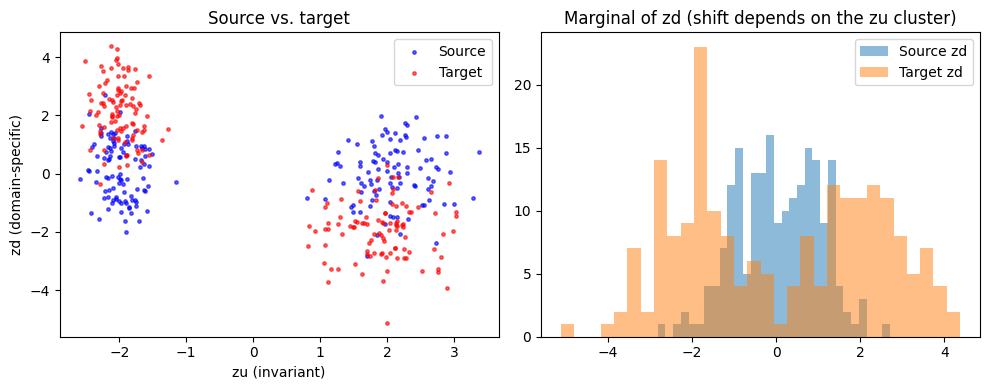

In [8]:
OUT_1D = RESULTS_ROOT / "1d"

Xs_1d, Xt_1d = make_data(n=100, shift=2.0, dim_zu=1, dim_zd=1,
                         zu_locs=(-2.0, 2.0), zu_scales=(0.25, 0.5),
                         dist_zu="normal", dist_zd="normal", seed=SEED)
print("Xs:", Xs_1d.shape, " Xt:", Xt_1d.shape)

# Quick look at the raw data
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(Xs_1d[:, 0], Xs_1d[:, 1], c="blue", s=6, alpha=0.6, label="Source")
axes[0].scatter(Xt_1d[:, 0], Xt_1d[:, 1], c="red", s=6, alpha=0.6, label="Target")
axes[0].set_xlabel("zu (invariant)"); axes[0].set_ylabel("zd (domain-specific)")
axes[0].set_title("Source vs. target"); axes[0].legend()
axes[1].hist(Xs_1d[:, 1], bins=30, alpha=0.5, label="Source zd")
axes[1].hist(Xt_1d[:, 1], bins=30, alpha=0.5, label="Target zd")
axes[1].set_title("Marginal of zd (shift depends on the zu cluster)"); axes[1].legend()
plt.tight_layout(); plt.show()

In [9]:
df_1d = run_experiment(Xs_1d, Xt_1d, out_dir=OUT_1D, reg=1e-4, ot_method="sinkhorn",
                       plot_kinds=("scatter", "coupling", "marginals"))
df_1d.round(4)

[matching_zu ] alpha=1    beta=0  projection=full


[matching_zu ] alpha=1    beta=0  projection=zd_only


[strong_cond ] alpha=10   beta=1  projection=full


[strong_cond ] alpha=10   beta=1  projection=zd_only


[balanced    ] alpha=1    beta=1  projection=full


...

[zd_dominant ] alpha=0.1  beta=1  projection=full


[zd_dominant ] alpha=0.1  beta=1  projection=zd_only


[transfer_zd ] alpha=0    beta=1  projection=full


[transfer_zd ] alpha=0    beta=1  projection=zd_only


,config,method,value,W_zu,W_zd,mmd,wasserstein2,delta_zu,cross_mass,recon_err,energy,silhouette
0,1_0,full,raw,0.0103,0.5435,0.0521,0.7258,0.0915,0.0000,0.9892,0.1608,0.8865
1,1_0,zd_only,raw,0.0936,0.5435,0.0556,0.7374,0.0000,0.0000,0.9936,0.1746,0.8891
2,10_1,full,raw,0.0121,0.0373,0.0000,0.0998,0.1088,0.0000,1.2910,0.0146,0.8866
3,10_1,zd_only,raw,0.0936,0.0373,0.0021,0.1786,0.0000,0.0000,1.2992,0.0465,0.8891
4,1_1,full,raw,0.1378,1.4054,0.2559,1.7127,0.1898,0.0000,1.9031,0.3905,0.8977
5,1_1,zd_only,raw,0.0936,1.4054,0.2472,1.6911,0.0000,0.0000,1.9118,0.3971,0.8891
6,0.1_1,full,raw,0.1607,1.3682,0.2476,1.7260,0.4434,0.0000,2.1249,0.3986,0.8314
7,0.1_1,zd_only,raw,0.0936,1.3682,0.2571,1.8650,0.0000,0.0000,2.0733,0.3850,0.8891
8,0_1,full,raw,0.2413,1.2266,0.1914,1.3785,2.0554,0.5135,3.0834,0.4387,0.3078
9,0_1,zd_only,raw,0.0936,1.2266,0.2437,1.9829,0.0000,0.5135,2.2140,0.3401,0.8891


### Supplementary Fig. S1 - counterfactual generations (1-D)

Rows: projection on the full latent vector (top) vs. on $z_d$ only (bottom).
Columns: $(\alpha,\beta)$ = (1,0), (10,1), (1,1), (0.1,1), (0,1).

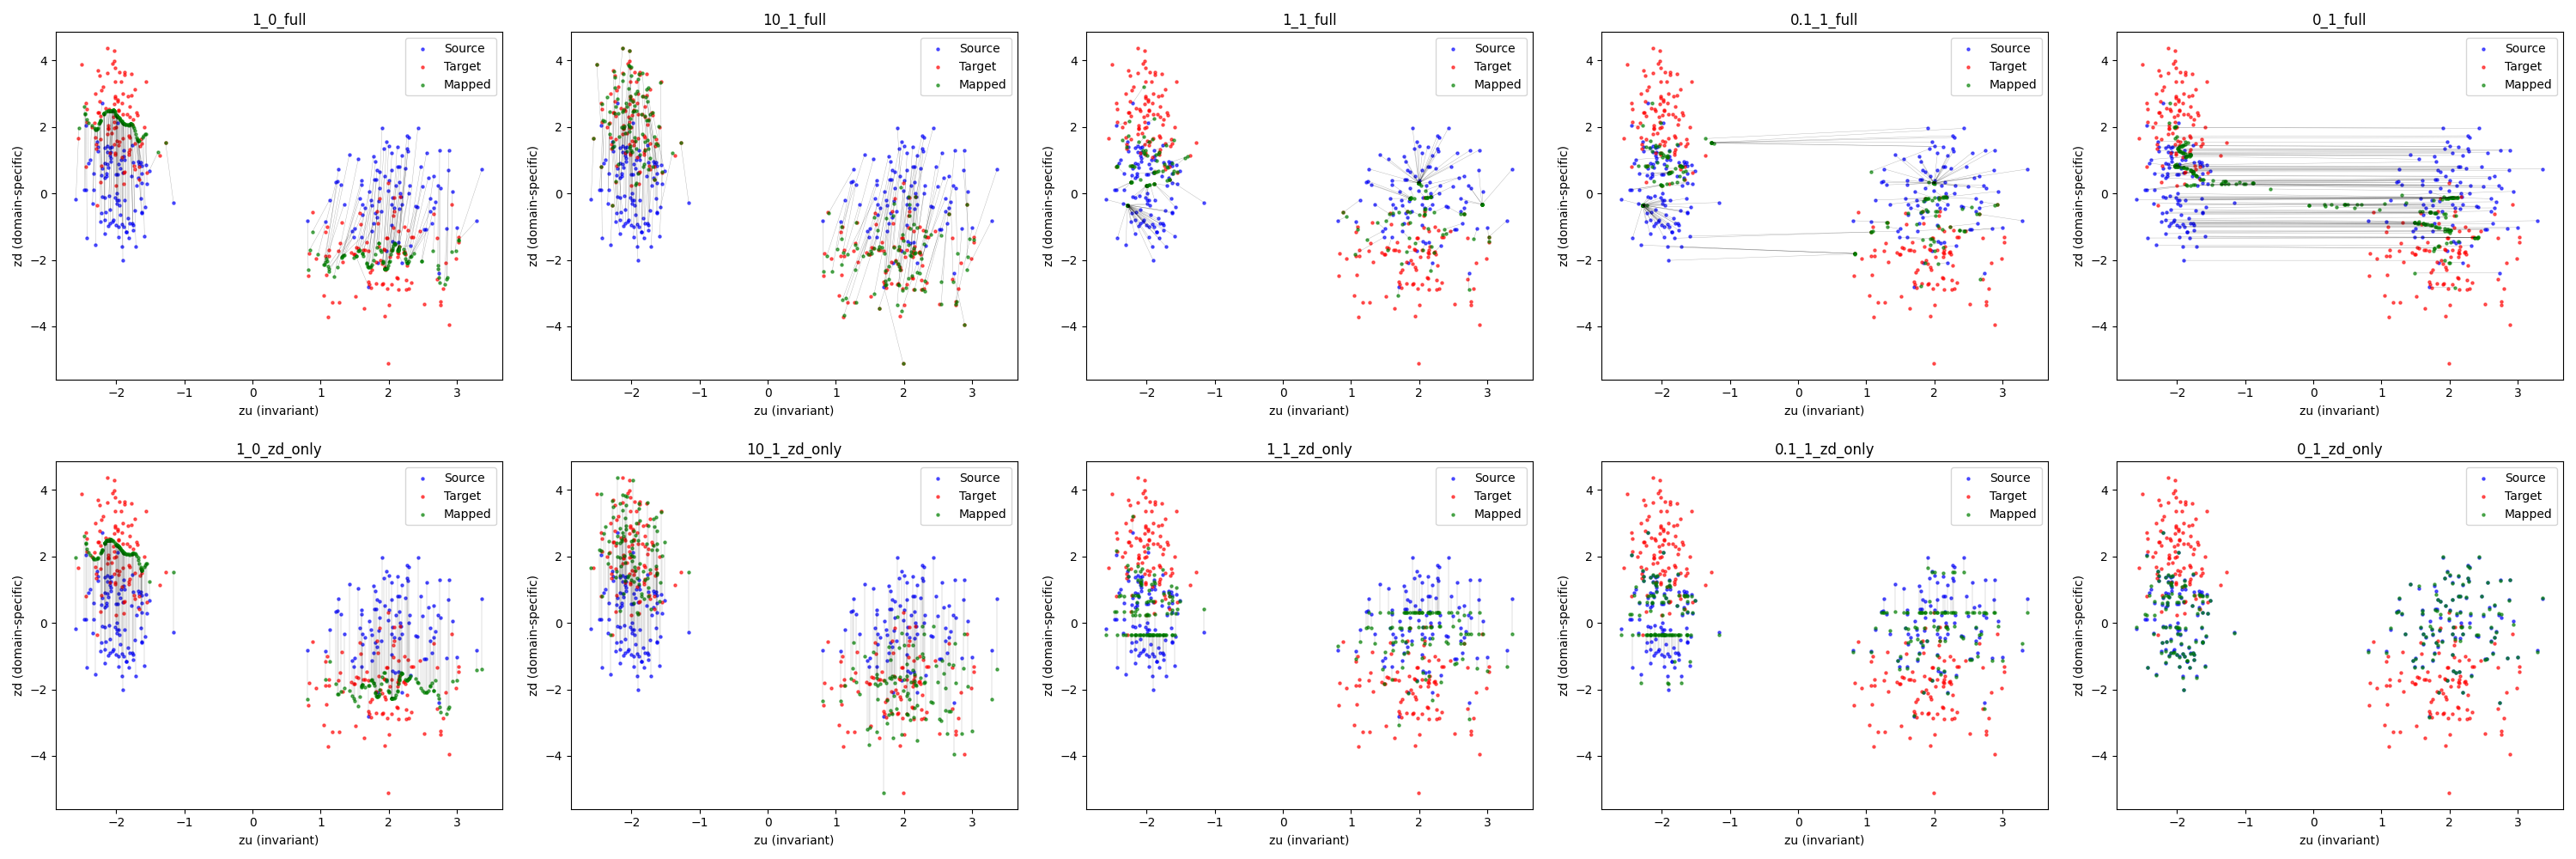

In [10]:
grids_1d = make_grids(df_1d, OUT_1D, kinds=("scatter", "coupling", "marginals"))
show(grids_1d["scatter"])

### Supplementary Fig. S2 - marginal distributions of $z_u$ and $z_d$ (1-D)

Rows: $(\alpha,\beta)$ configurations. Columns: full projection (left) vs. $z_d$-only projection (right).

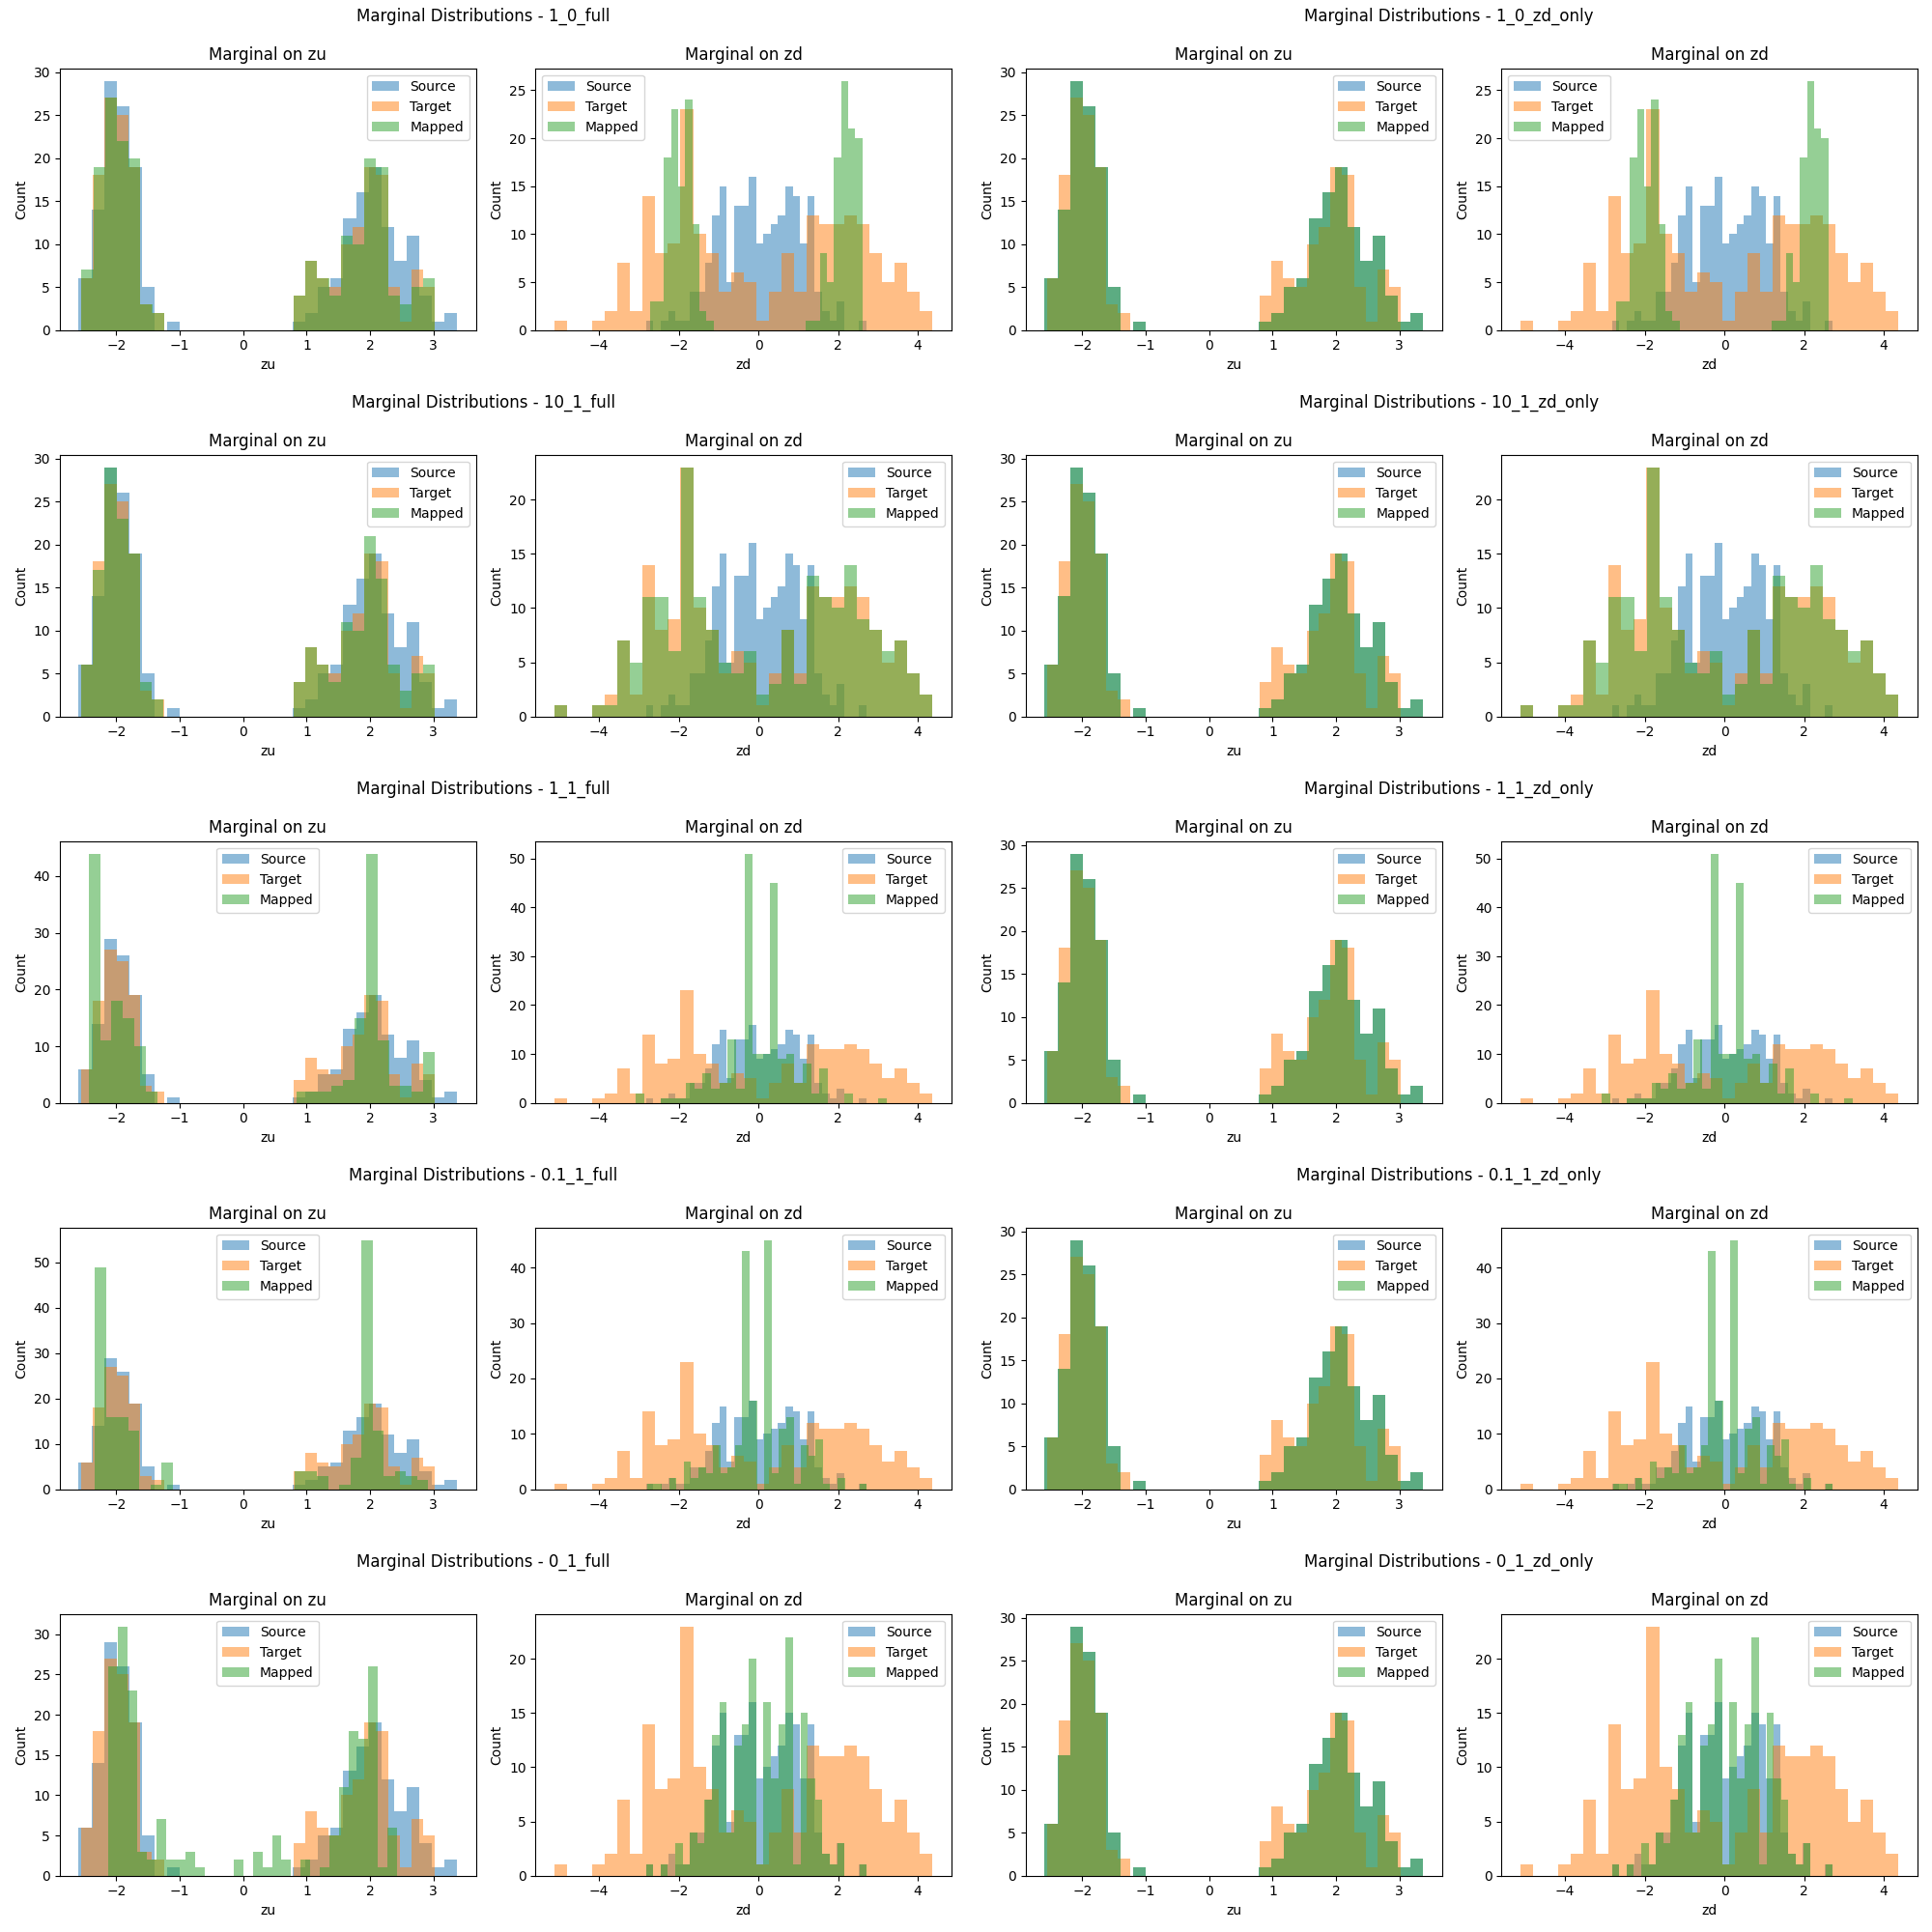

In [11]:
show(grids_1d["marginals"], width=1000)

### Transport plans

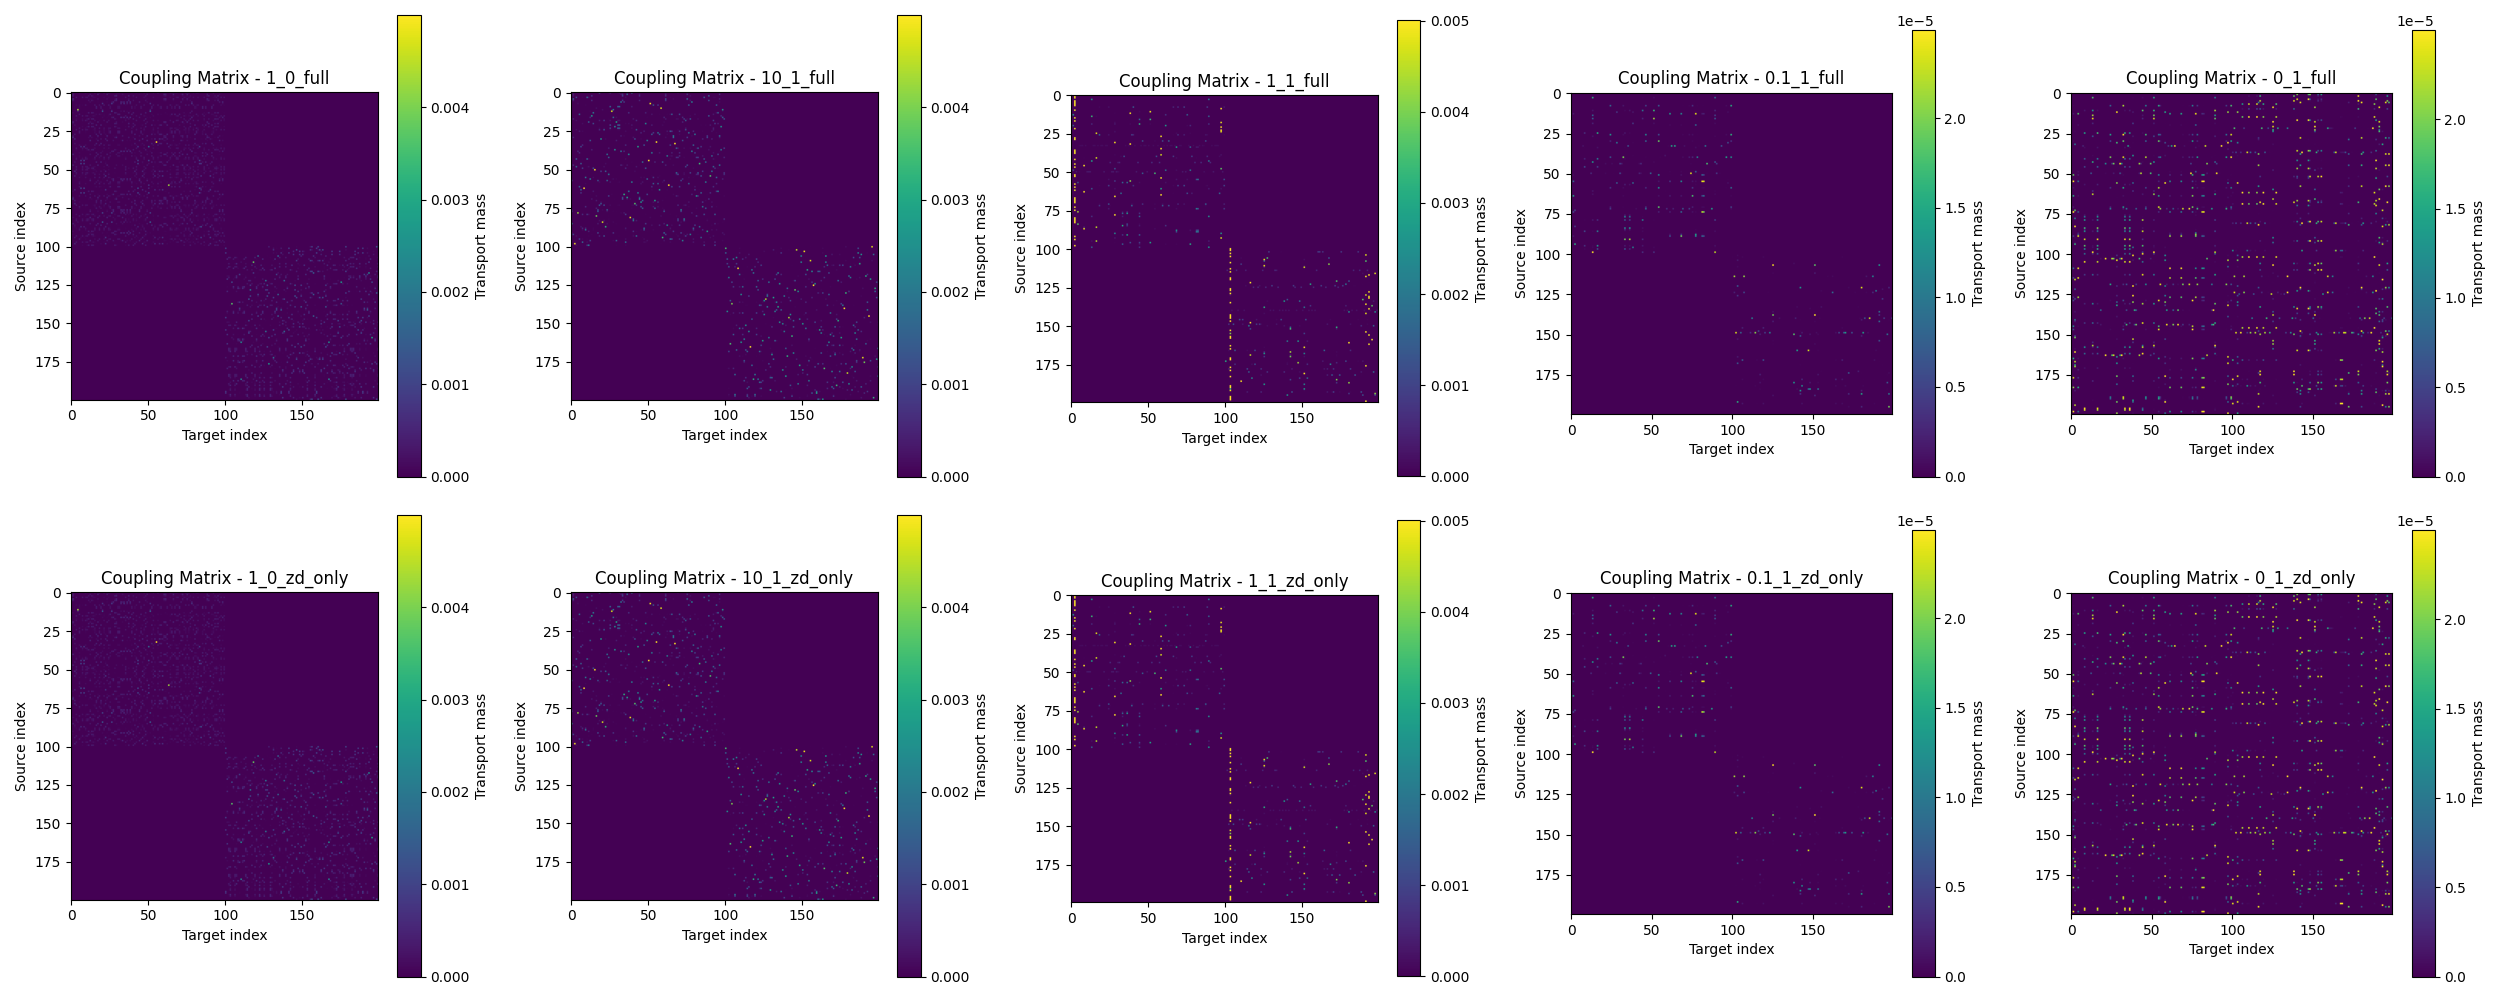

In [12]:
show(grids_1d["coupling"])

### Metric comparison (1-D)

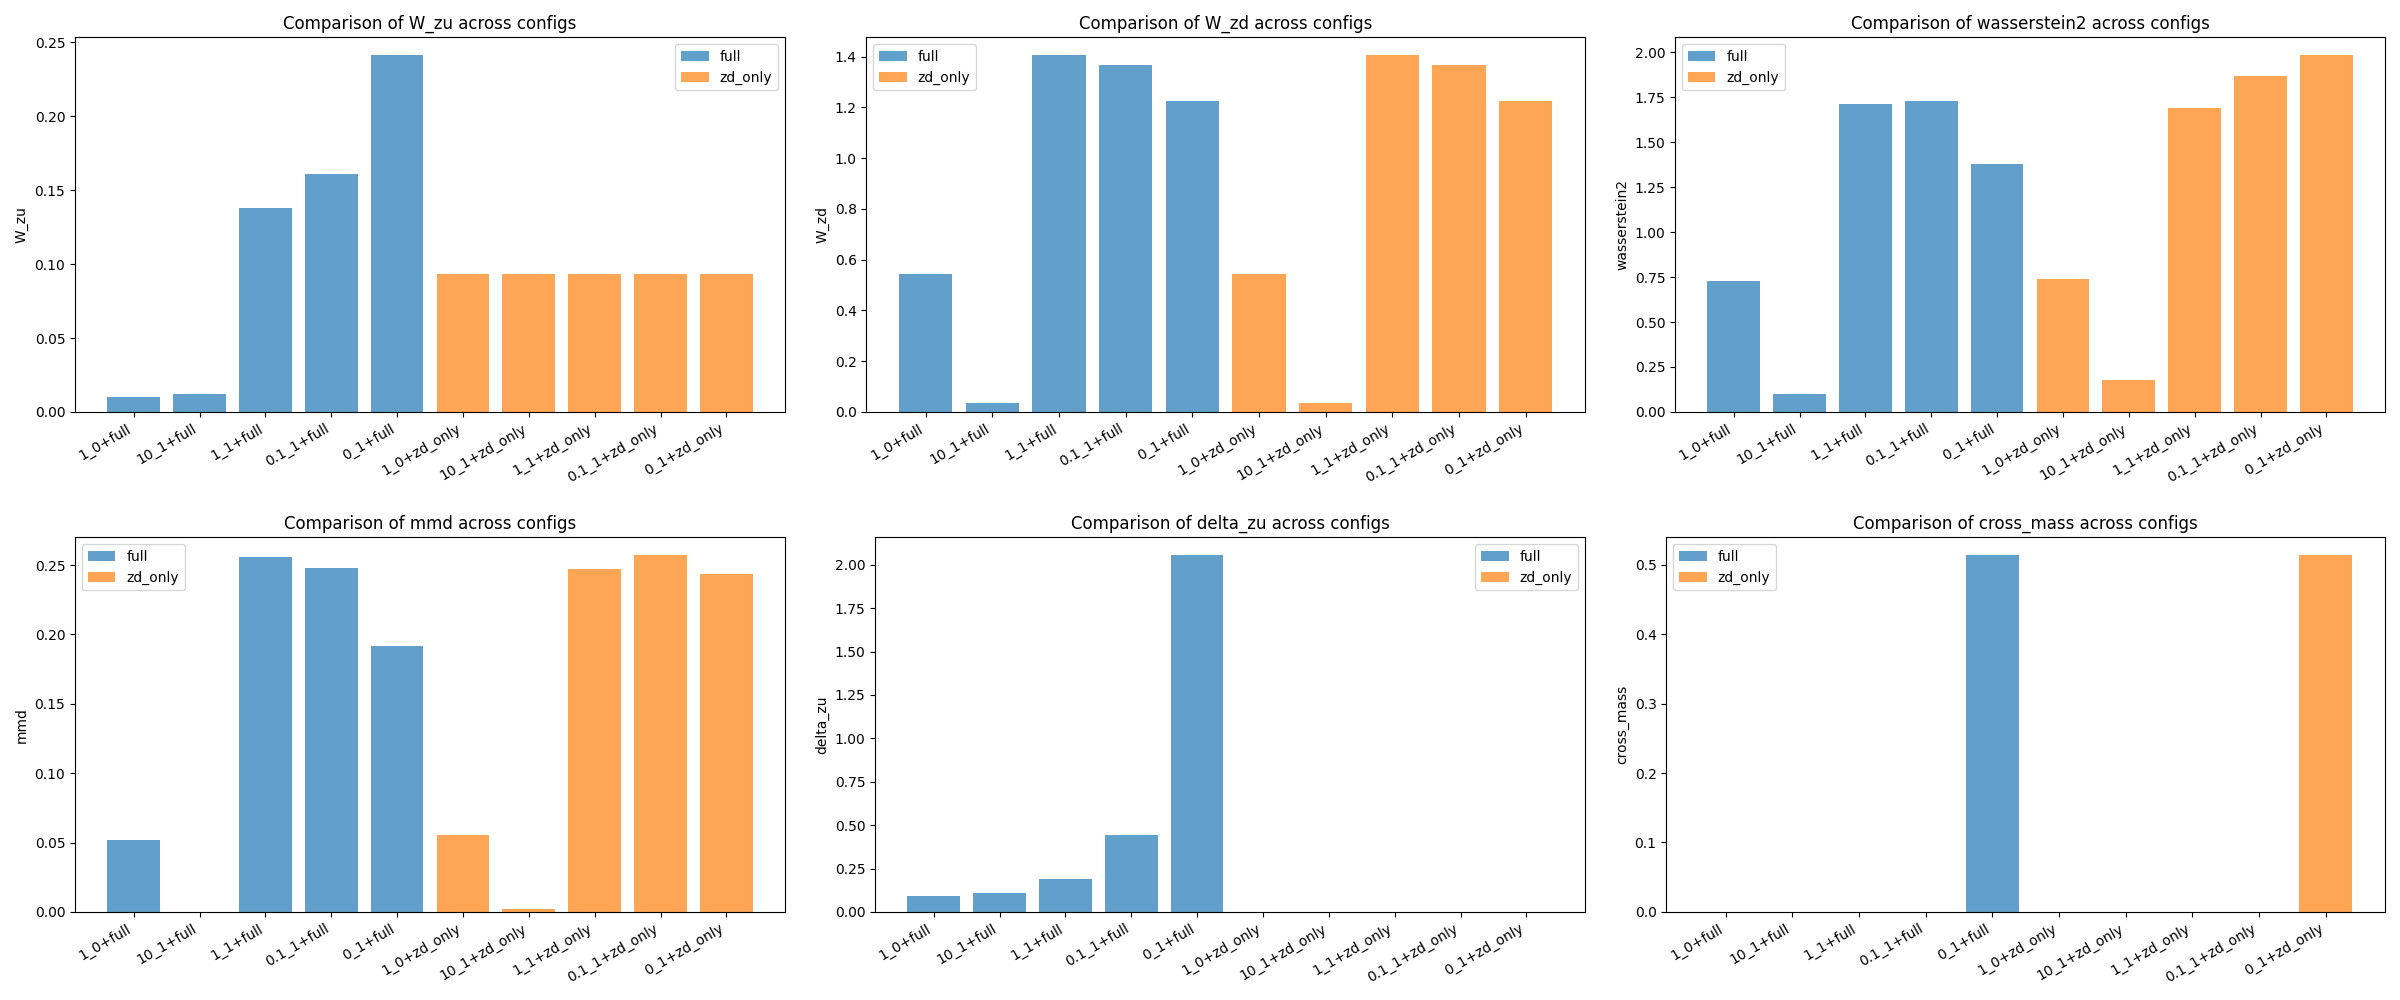

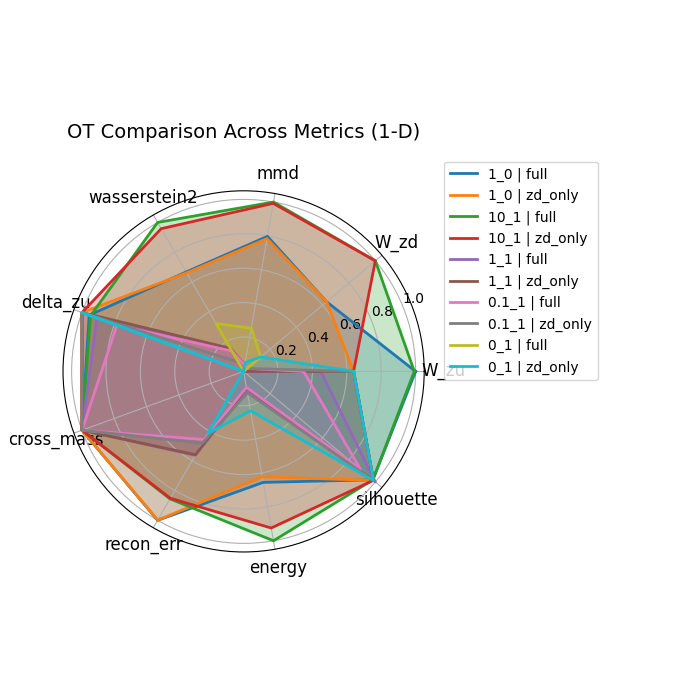

In [13]:
bar_files_1d = plot_metric_bars(df_1d, ["W_zu", "W_zd", "wasserstein2", "mmd", "delta_zu", "cross_mass"], OUT_1D)
show(concat_grid(bar_files_1d, n_rows=2, n_cols=3, save_path=OUT_1D / "comparison_bars_grid.png"))
plot_radar_chart(df_1d, title="OT Comparison Across Metrics (1-D)", save=OUT_1D / "comparison_radar_chart.png")
show(OUT_1D / "comparison_radar_chart.png", width=600)

---
# Part B. Multi-dimensional latent space ($z_u, z_d \in \mathbb{R}^3$)

Settings (identical to `final_mv.py`): $n=100$ per cluster, $\delta=2$, Normal distributions,
$z_u$ clusters $\mathcal N(-\mathbf 1, 0.5^2 I)$ and $\mathcal N(+\mathbf 1, 0.5^2 I)$,
Sinkhorn with `reg = 0.01`, seed 32. Results are visualised with a UMAP embedding fitted jointly
on source, target and mapped points.

In [14]:
OUT_MD = RESULTS_ROOT / "md"

Xs_md, Xt_md = make_data(n=100, shift=2.0, dim_zu=3, dim_zd=3,
                         zu_locs=(-1.0, 1.0), zu_scales=(0.5, 0.5),
                         dist_zu="normal", dist_zd="normal", seed=SEED)
print("Xs:", Xs_md.shape, " Xt:", Xt_md.shape)

df_md = run_experiment(Xs_md, Xt_md, out_dir=OUT_MD, reg=0.01, ot_method="sinkhorn",
                       plot_kinds=("embedding",), embed_method="umap")
df_md.round(4)

Xs: (200, 6)  Xt: (200, 6)
[matching_zu ] alpha=1    beta=0  projection=full


[matching_zu ] alpha=1    beta=0  projection=zd_only


[strong_cond ] alpha=10   beta=1  projection=full


[strong_cond ] alpha=10   beta=1  projection=zd_only


[balanced    ] alpha=1    beta=1  projection=full


...

[zd_dominant ] alpha=0.1  beta=1  projection=full


[zd_dominant ] alpha=0.1  beta=1  projection=zd_only


[transfer_zd ] alpha=0    beta=1  projection=full


[transfer_zd ] alpha=0    beta=1  projection=zd_only


,config,method,value,W_zu,W_zd,mmd,wasserstein2,delta_zu,cross_mass,recon_err,energy,silhouette
0,1_0,full,raw,0.1097,0.7173,0.2015,1.7193,0.3111,0.0001,2.0640,0.1978,0.7375
1,1_0,zd_only,raw,0.0367,0.7173,0.1386,1.7392,0.0000,0.0001,2.1615,0.2071,0.6825
2,10_1,full,raw,0.1123,0.4550,0.0863,1.2781,0.3341,0.0038,2.2346,0.1232,0.7384
3,10_1,zd_only,raw,0.0367,0.4550,0.0549,1.3207,0.0000,0.0038,2.3304,0.1250,0.6825
4,1_1,full,raw,0.1613,0.1875,0.0235,1.0961,0.9641,0.1743,3.4467,0.0859,0.5875
5,1_1,zd_only,raw,0.0367,0.1875,0.0119,1.5993,0.0000,0.1743,3.4848,0.0541,0.6825
6,0.1_1,full,raw,0.2060,0.2009,0.0265,1.1882,1.8512,0.4355,4.8520,0.1247,0.2883
7,0.1_1,zd_only,raw,0.0367,0.2009,0.0263,2.3355,0.0000,0.4355,4.6714,0.0618,0.6825
8,0_1,full,raw,0.2082,0.2037,0.0268,1.2189,2.0395,0.4858,5.1017,0.1258,0.2337
9,0_1,zd_only,raw,0.0367,0.2037,0.0308,2.4344,0.0000,0.4858,4.8624,0.0626,0.6825


### Supplementary Fig. S3 - counterfactual generations (multi-dimensional, UMAP)

Rows: full projection (top) vs. $z_d$-only projection (bottom).
Columns: $(\alpha,\beta)$ = (1,0), (10,1), (1,1), (0.1,1), (0,1).

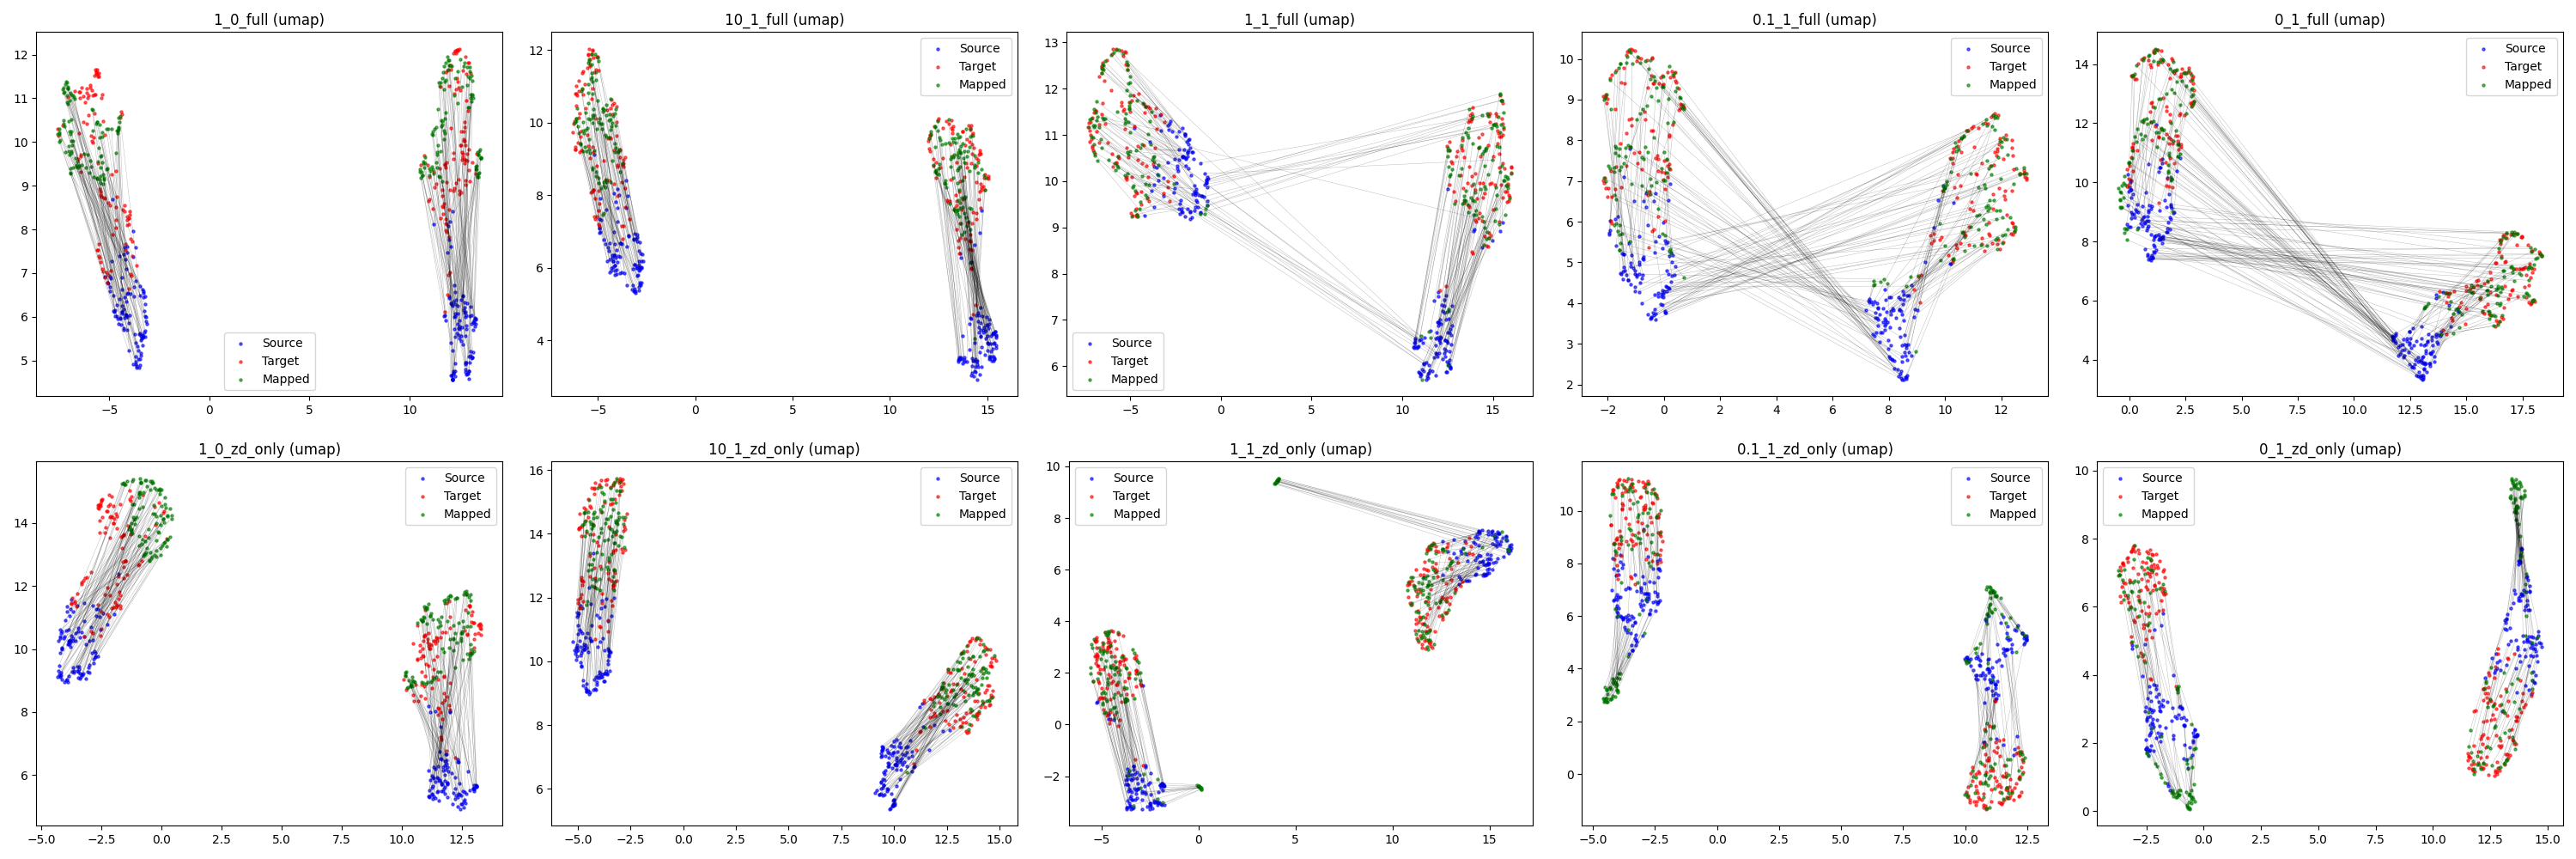

In [15]:
grids_md = make_grids(df_md, OUT_MD, kinds=("scatter",))
show(grids_md["scatter"])

### Metric comparison (multi-dimensional)

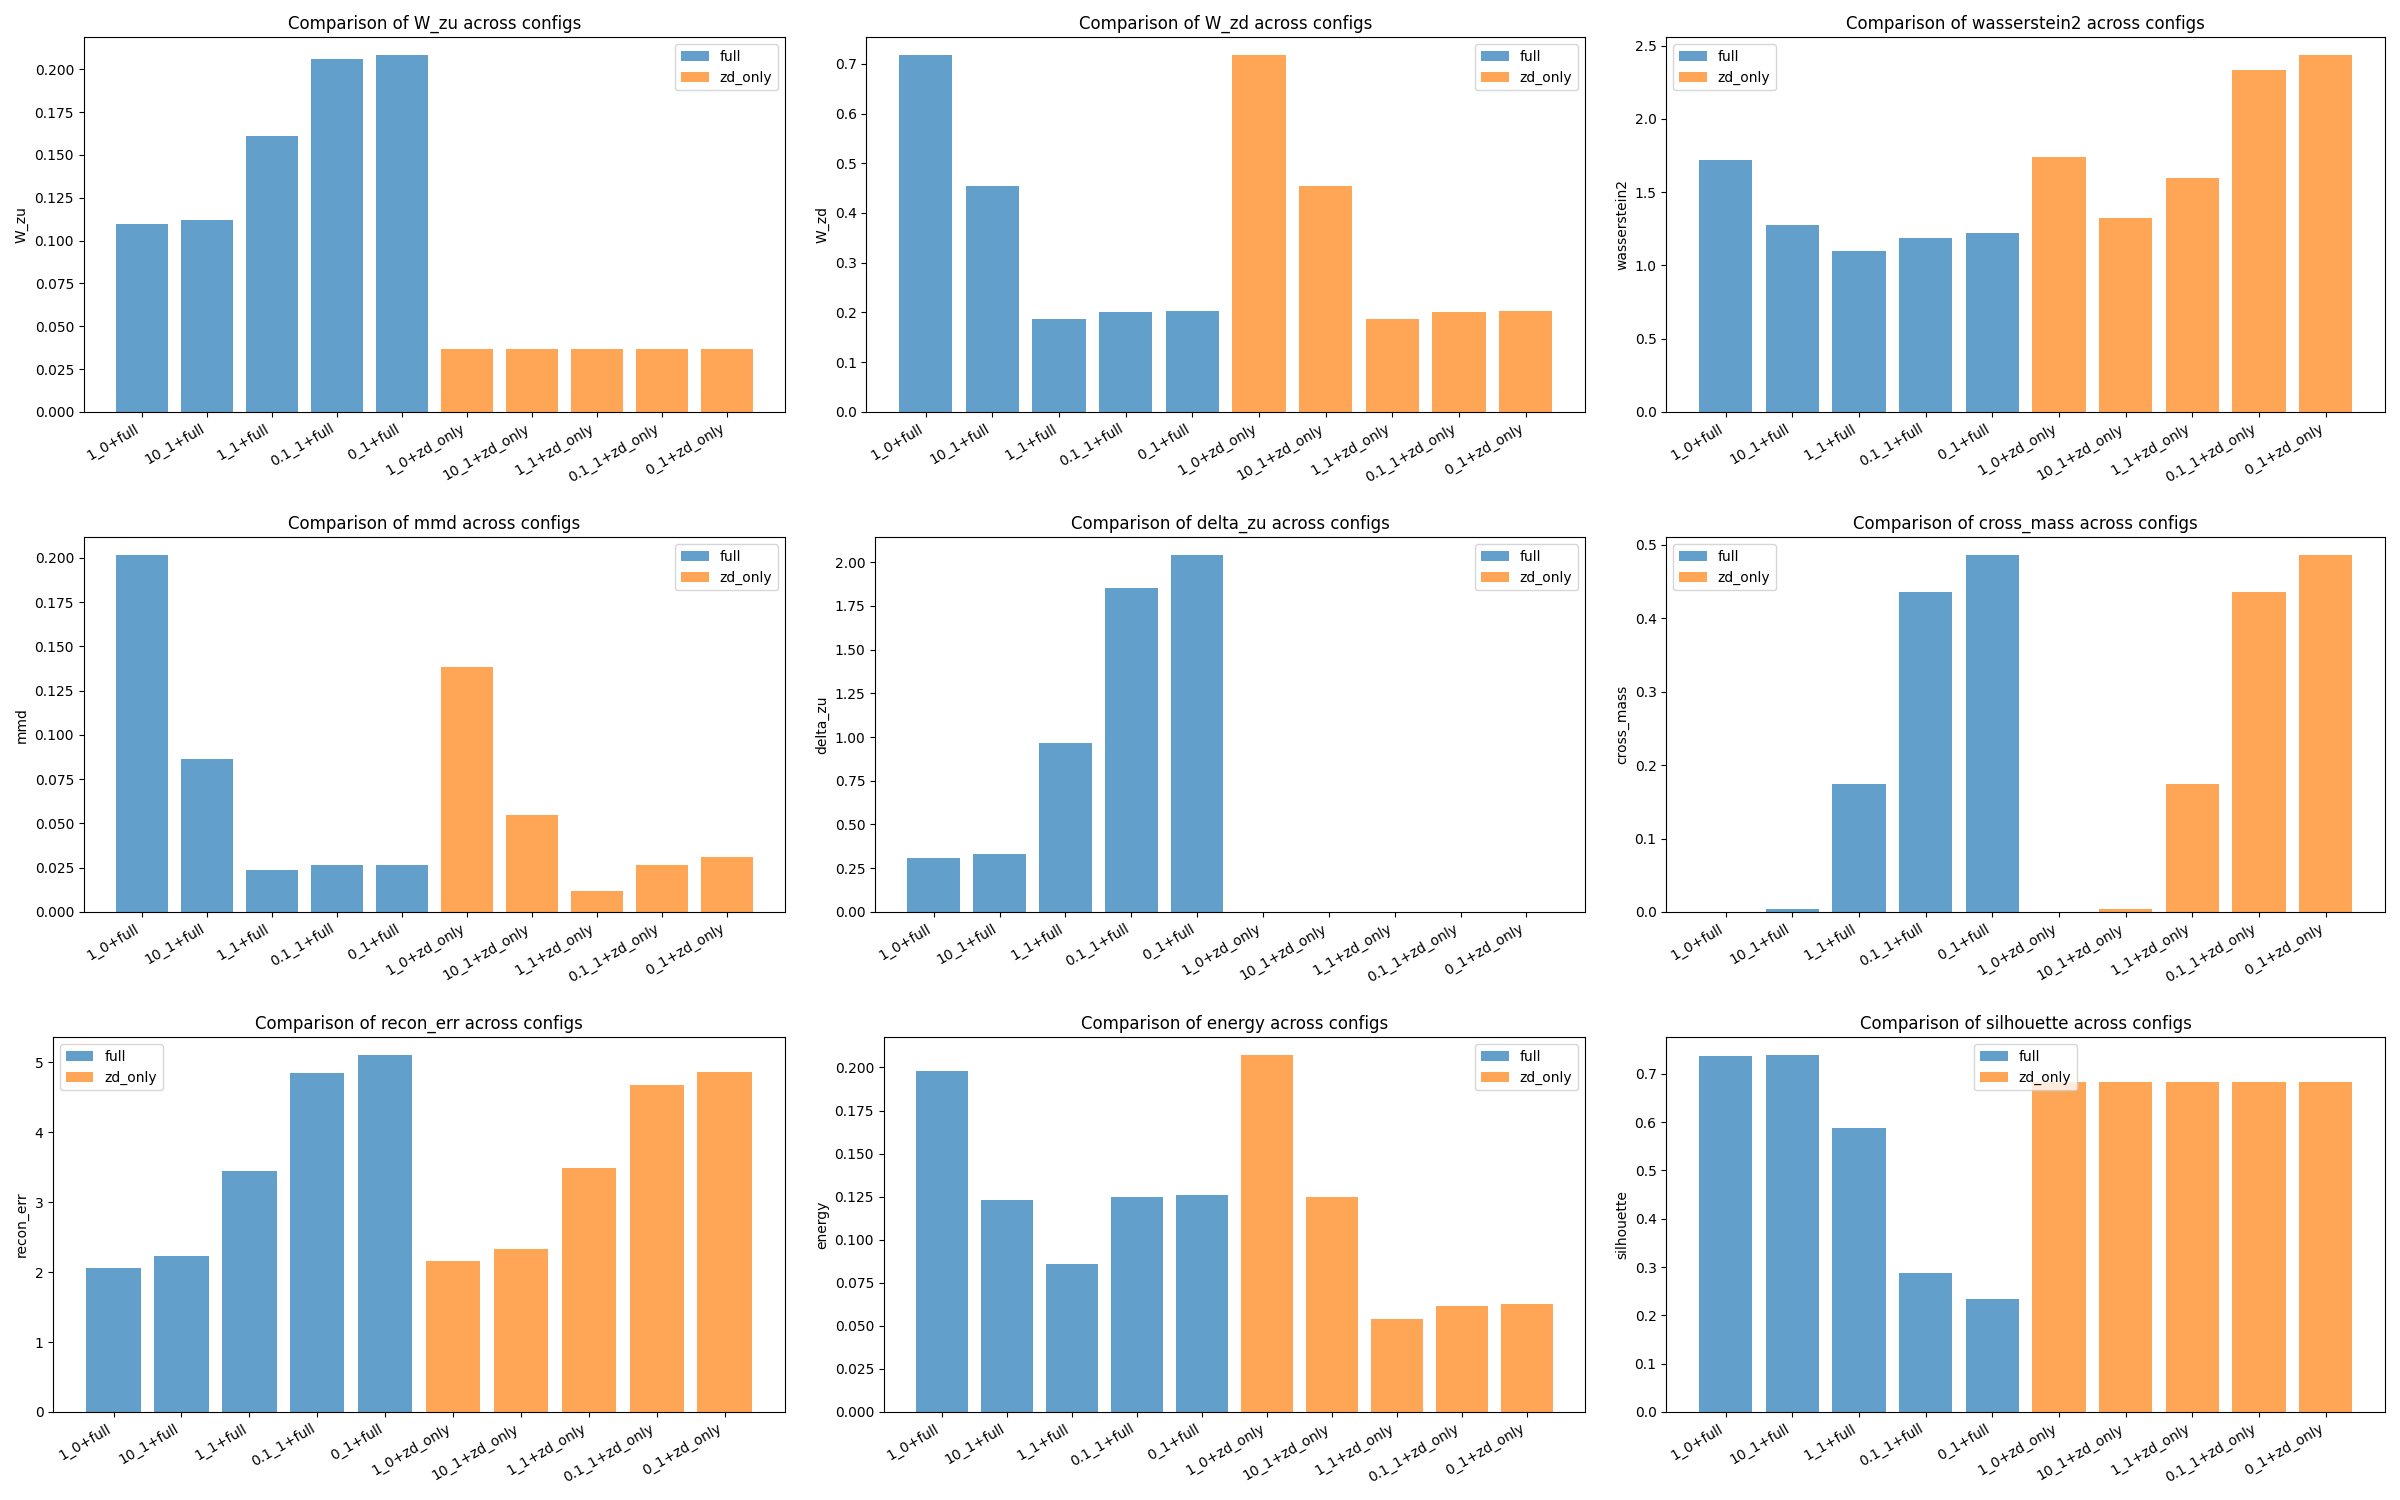

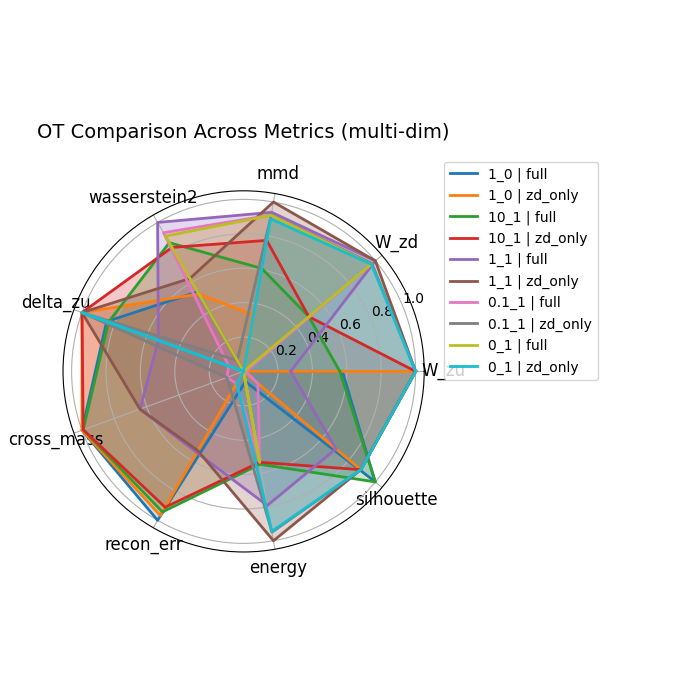

In [16]:
bar_files_md = plot_metric_bars(
    df_md, ["W_zu", "W_zd", "wasserstein2", "mmd", "delta_zu", "cross_mass", "recon_err", "energy", "silhouette"], OUT_MD)
show(concat_grid(bar_files_md, n_rows=3, n_cols=3, save_path=OUT_MD / "comparison_bars_grid.png"))
plot_radar_chart(df_md, title="OT Comparison Across Metrics (multi-dim)", save=OUT_MD / "comparison_radar_chart.png")
show(OUT_MD / "comparison_radar_chart.png", width=600)

---
## Take-aways

* **No / weak conditioning** ($\alpha = 0$ or $\alpha = 0.1$): substantial cross-cluster matching
  (large `cross_mass`, large `delta_zu`). The $z_d$ marginals can be aligned, but cells are matched
  across cell identities, i.e. the confounder leaks into the counterfactual. The problem is even
  more visible with the $z_d$-only projection, where the $z_u$ of a cell is kept while its $z_d$
  is borrowed from the wrong cluster.
* **Pure confounder matching** ($\beta = 0$): the $z_u$ marginals are matched perfectly, but the
  $z_d$ marginals are not transferred at all (large `W_zd`).
* **Strong conditioning** ($\alpha = 10, \beta = 1$): essentially no cross-cluster mass, $z_u$ is
  preserved, and $z_d$ is transferred within each cluster, which is the intended rank-preserving,
  within-cluster counterfactual matching.

An appropriate level of conditioning on the invariant latent factors is therefore crucial.